In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 0. MDP 模型
# ============================================================

gamma = 0.999
R_stop = 25.0

P = np.array([
    [0.98,  0.01,  0.01,  0.0],
    [0.01,  0.98,  0.01,  0.0],
    [0.005, 0.005, 0.985, 0.005],
    [0.0,   0.0,   0.0,   1.0]
])

# 继续时的奖励
r_continue = np.array([1.0, 1.0, 1.0, 0.0])

n_states = 4

In [3]:
# ============================================================
# (a) 评估指定策略：s1停止，其余状态继续
# ============================================================

# 构造策略对应的奖励向量
R_d = np.array([R_stop, 1.0, 1.0, 0.0])

# 构造策略对应的转移矩阵
P_d = P.copy()
P_d[0, :] = 0.0

# ------------------------------------------------------------
# (a)(i) 直接求解线性方程组
# ------------------------------------------------------------

V_exact = np.linalg.solve(
    np.eye(n_states) - gamma * P_d,
    R_d
)

print("=" * 55)
print("(a)(i) 直接求解")
print("=" * 55)
print("价值函数：")
print(V_exact)


# ------------------------------------------------------------
# (a)(ii) 同步迭代
# ------------------------------------------------------------

def jacobi_iteration(tol=1e-6, max_iter=1000000):

    V = np.zeros(n_states)

    # 利用压缩映射误差界控制价值函数误差
    difference_tol = (1 - gamma) / gamma * tol

    for k in range(1, max_iter + 1):

        V_new = R_d + gamma * P_d @ V

        difference = np.max(np.abs(V_new - V))

        V = V_new.copy()

        if difference <= difference_tol:
            break

    return V, k, difference


V_jacobi, iter_jacobi, diff_jacobi = jacobi_iteration()

print("\n" + "=" * 55)
print("(a)(ii) 同步迭代")
print("=" * 55)
print("价值函数：")
print(V_jacobi)
print("迭代次数：", iter_jacobi)
print("相邻两次迭代的差：", diff_jacobi)
print("与精确解的最大误差：",
      np.max(np.abs(V_jacobi - V_exact)))


# ------------------------------------------------------------
# (a)(iii) Gauss-Seidel 分量迭代
# ------------------------------------------------------------

def gauss_seidel_iteration(tol=1e-6, max_iter=1000000):

    V = np.zeros(n_states)

    for k in range(1, max_iter + 1):

        V_old = V.copy()

        # 按 s1, s2, s3, s4 顺序逐个更新
        for i in range(n_states):

            V[i] = R_d[i] + gamma * P_d[i] @ V

        difference = np.max(np.abs(V - V_old))

        if difference < tol:
            break

    return V, k, difference


V_gs, iter_gs, diff_gs = gauss_seidel_iteration()

print("\n" + "=" * 55)
print("(a)(iii) Gauss-Seidel 迭代")
print("=" * 55)
print("价值函数：")
print(V_gs)
print("迭代次数：", iter_gs)
print("相邻两次迭代的差：", diff_gs)
print("与精确解的最大误差：",
      np.max(np.abs(V_gs - V_exact)))

(a)(i) 直接求解
价值函数：
[ 25.         109.34695204 104.53944482   0.        ]

(a)(ii) 同步迭代
价值函数：
[ 25.         109.34695195 104.53944473   0.        ]
迭代次数： 1891
相邻两次迭代的差： 9.928129429681576e-10
与精确解的最大误差： 8.934414097439003e-08

(a)(iii) Gauss-Seidel 迭代
价值函数：
[ 25.         109.34686296 104.53935607   0.        ]
迭代次数： 1262
相邻两次迭代的差： 9.931456617096046e-07
与精确解的最大误差： 8.907330952467873e-05


In [5]:
# ============================================================
# (b) 求解最优停止问题
# ============================================================

def optimal_stopping(R_stop, tol=1e-8, max_iter=1000000):

    V = np.zeros(n_states)

    difference_tol = (1 - gamma) / gamma * tol

    for k in range(1, max_iter + 1):

        # 继续的价值
        Q_continue = r_continue + gamma * P @ V

        V_new = Q_continue.copy()

        # s1、s2 可以选择停止
        V_new[0] = max(R_stop, Q_continue[0])
        V_new[1] = max(R_stop, Q_continue[1])

        difference = max(V_new - V) - min(V_new - V)

        V = V_new.copy()

        if difference <= difference_tol:
            break

    # 计算最终的停止和继续价值
    Q_continue = r_continue + gamma * P @ V

    policy = np.array([
        "停止" if R_stop > Q_continue[0] else "继续",
        "停止" if R_stop > Q_continue[1] else "继续",
        "继续",
        "继续"
    ])

    return V, policy, k


V_star, policy_star, iter_optimal = optimal_stopping(R_stop)

print("\n" + "=" * 55)
print("(b) 最优停止策略")
print("=" * 55)
print("最优价值函数：")
print(V_star)

print("\n最优策略：")
for i in range(n_states):
    print(f"s{i+1}: {policy_star[i]}")

print("迭代次数：", iter_optimal)


(b) 最优停止策略
最优价值函数：
[342.33914837 342.33914837 276.50723129   0.        ]

最优策略：
s1: 继续
s2: 继续
s3: 继续
s4: 继续
迭代次数： 7945



(c) 停止奖励敏感性分析
临界停止奖励： 342.33914837617834

不同停止奖励下的最优策略：
R=25.000000, V1=342.3391, V2=342.3391, V3=276.5072, 策略=['继续' '继续']
R=100.000000, V1=342.3391, V2=342.3391, V3=276.5072, 策略=['继续' '继续']
R=200.000000, V1=342.3391, V2=342.3391, V3=276.5072, 策略=['继续' '继续']
R=300.000000, V1=342.3391, V2=342.3391, V3=276.5072, 策略=['继续' '继续']
R=342.339148, V1=342.3391, V2=342.3391, V3=276.5072, 策略=['停止' '停止']
R=400.000000, V1=400.0000, V2=400.0000, V3=312.5430, 策略=['停止' '停止']
R=500.000000, V1=500.0000, V2=500.0000, V3=375.0391, 策略=['停止' '停止']


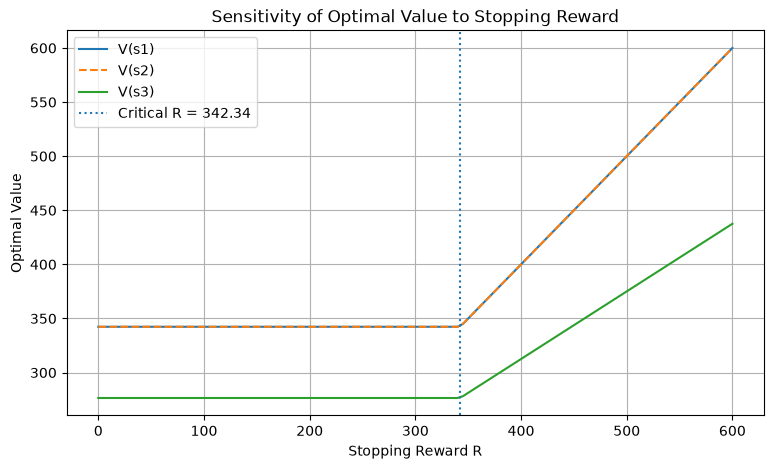

e:\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32487 (\N{CJK UNIFIED IDEOGRAPH-7EE7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32493 (\N{CJK UNIFIED IDEOGRAPH-7EED}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20572 (\N{CJK UNIFIED IDEOGRAPH-505C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 27490 (\N{CJK UNIFIED IDEOGRAPH-6B62}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


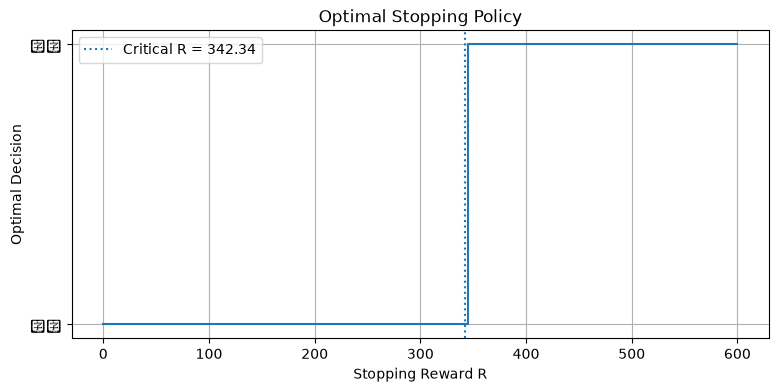

In [6]:
# ============================================================
# (c) 停止奖励敏感性分析
# ============================================================

# 通过全继续策略求解临界值
V_continue = np.linalg.solve(
    np.eye(n_states) - gamma * P,
    r_continue
)

R_critical = V_continue[0]

print("\n" + "=" * 55)
print("(c) 停止奖励敏感性分析")
print("=" * 55)

print("临界停止奖励：", R_critical)

# 测试不同停止奖励
R_values = [25, 100, 200, 300, R_critical, 400, 500]

print("\n不同停止奖励下的最优策略：")

for R_test in R_values:

    V_test, policy_test, _ = optimal_stopping(R_test)

    print(
        f"R={R_test:.6f}, "
        f"V1={V_test[0]:.4f}, "
        f"V2={V_test[1]:.4f}, "
        f"V3={V_test[2]:.4f}, "
        f"策略={policy_test[:2]}"
    )


# ============================================================
# 绘制停止奖励与价值函数的关系
# ============================================================

R_grid = np.linspace(0, 600, 121)

V1_list = []
V2_list = []
V3_list = []

for R_test in R_grid:

    V_test, _, _ = optimal_stopping(R_test)

    V1_list.append(V_test[0])
    V2_list.append(V_test[1])
    V3_list.append(V_test[2])


plt.figure(figsize=(9, 5))

plt.plot(R_grid, V1_list, label="V(s1)")
plt.plot(R_grid, V2_list, "--", label="V(s2)")
plt.plot(R_grid, V3_list, label="V(s3)")

plt.axvline(
    R_critical,
    linestyle=":",
    label=f"Critical R = {R_critical:.2f}"
)

plt.xlabel("Stopping Reward R")
plt.ylabel("Optimal Value")
plt.title("Sensitivity of Optimal Value to Stopping Reward")

plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 绘制最优策略随停止奖励的变化
# ============================================================

plt.figure(figsize=(9, 4))

stop_indicator = [
    1 if R_test > R_critical else 0
    for R_test in R_grid
]

plt.step(
    R_grid,
    stop_indicator,
    where="post"
)

plt.axvline(
    R_critical,
    linestyle=":",
    label=f"Critical R = {R_critical:.2f}"
)

plt.yticks([0, 1], ["继续", "停止"])
plt.xlabel("Stopping Reward R")
plt.ylabel("Optimal Decision")
plt.title("Optimal Stopping Policy")

plt.legend()
plt.grid(True)
plt.show()
